# NB5a — Forecasting development on the validation units: LightGBM setting and the R1 reference

Guide §3.7–§3.9, §5.1–§5.3, D09, D12, D21, D25, D33. Reads `results/nb2_panel/`, `results/nb3_index/` (frozen part 1) and `results/nb4_sensor/`; writes `results/nb5a_dev/`. **No test event is forecast or scored here**: the test run follows the protocol freeze (D21, D33).

**Rules fixed before any number below:**
0. *Formulation* (D34, chosen on the validation units in `NB5a_variants`): each LightGBM model forecasts the change of the index from its current value, k(t + h) − k(t), and k(t) is added back.
1. *LightGBM setting* (guide §5.2): the 18 settings of the grid (num_leaves 15/31/63, learning rate 0.03/0.05, min_data_in_leaf 50/100/200) are compared by time-series cross-validation on the development index, the censored index of the validation unit with the most donors, restricted to data before the first test day. Folds: targets in July, August and September 2021, each trained on all earlier pairs from 15 May 2021. Criterion: mean pinball loss over 9 quantiles, 6 horizons and 3 folds; the lowest wins. Ties within 1e-6 are broken toward the guide's starting values (31, 0.03, 100), parameter by parameter, then toward fewer leaves (completed in D33 after an exact tie). This is the hyperparameter budget every trained model gets (R1): 18 settings × 3 folds.
2. *Validation run* with the chosen setting: each validation unit is forecast over its first 90 days from origins s, s + 30 d and s + 60 d (expanding training windows), with its frozen prior G2 and uncertainty set, as 200 members.
3. *R1 reference*: the median over the 10 validation units of the nRMSE at 1 h (full daily window, member mean, on the slots where every model has a forecast). PVSetFormer becomes the main index forecaster only if its value, computed the same way, is lower (D25).

In [1]:
import os, sys, time, json, hashlib
from pathlib import Path
import numpy as np, pandas as pd, yaml
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT / 'src'))
os.environ['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + os.environ.get('PYTHONPATH', '')   # joblib workers
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count()))
from joblib import Parallel, delayed
from pvcold import config as C, audit as A, fleet as F, forecast as FC
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
N_JOBS = os.cpu_count()
t0 = time.time()
nb3 = json.loads((C.RESULTS / 'nb3_index' / 'summary.json').read_text())
FROZEN1_TEXT = (C.RESULTS / 'nb3_index' / 'frozen_config_part1.yaml').read_bytes().decode('utf-8')
assert hashlib.sha256(FROZEN1_TEXT.encode()).hexdigest() == nb3['frozen1_sha256'], 'frozen part 1 changed'
nb4 = json.loads((C.RESULTS / 'nb4_sensor' / 'summary.json').read_text())
assert hashlib.sha256((C.RESULTS / 'nb4_sensor' / 'sensor_config.yaml').read_bytes()).hexdigest() == nb4['sensor_config_sha256']
frozen1 = yaml.safe_load(FROZEN1_TEXT); PRIOR = frozen1['prior_variant']
ALT = json.loads((C.RESULTS / 'nb1_audit' / 'summary.json').read_text())['campus_altitude_m']
p = F.load_panel(); del p['targets15_kW']             # donors for the uncertainty sets; no target series
E = p['events'].set_index('event'); U = p['units']
VAL = E.index[E.set == 'validation'].tolist()
idx = {k: pd.read_parquet(C.RESULTS / 'nb3_index' / f'{k}.parquet').set_index('time') for k in ['k_cens', 'sigma', 'c', 'n']}
geo15 = p['geometry15']
pri3 = pd.read_csv(C.RESULTS / 'nb3_index' / 'priors.csv').set_index('event')
gains3 = pd.read_csv(C.RESULTS / 'nb3_index' / 'gains.csv')
DEV = E.loc[VAL].sort_values(['n_donors', 'start']).index[-1]      # most donors (latest start on a tie)
print(len(VAL), 'validation units; development index:', DEV, '(', int(E.loc[DEV, 'n_donors']), 'donors ) | workers:', N_JOBS)
print('frozen part 1', nb3['frozen1_sha256'][:12], '| sensor config', nb4['sensor_config_sha256'][:12], '| prior', PRIOR)

10 validation units; development index: SQ Apartment25-36 ( 16 donors ) | workers: 8
frozen part 1 cb671b7f6713 | sensor config 4c47bfac9fa3 | prior G2


## Rule 1 — LightGBM setting by time-series cross-validation (development index, before the first test day)

In [2]:
S_dev = FC.event_series(DEV, idx, geo15)
S_dev.loc[S_dev.index >= pd.Timestamp(C.FIRST_TEST_DAY), ['k', 'sigma', 'c', 'n']] = np.nan   # development data only
FOLDS = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in [('2021-07-01', '2021-08-01'), ('2021-08-01', '2021-09-01'), ('2021-09-01', '2021-10-01')]]
tasks = [(i, cfg, f, fs, fe) for i, cfg in enumerate(FC.LGB_GRID) for f, (fs, fe) in enumerate(FOLDS)]
t1 = time.time()
out = Parallel(n_jobs=N_JOBS)(delayed(FC.cv_task)(S_dev, cfg, fs, fe) for _, cfg, _, fs, fe in tasks)
rows = []
for (i, cfg, f, fs, fe), res in zip(tasks, out):
    for h, (pb, n, best) in res.items():
        rows.append({'config': i, **cfg, 'fold': f + 1, 'h': h, 'pinball': pb, 'n_valid': n,
                     'mean_best_rounds': float(np.mean(best)), 'share_one_round': float(np.mean(np.array(best) == 1))})
cv = pd.DataFrame(rows)
cvs = cv.groupby(['config', 'num_leaves', 'learning_rate', 'min_data_in_leaf'])['pinball'].mean().reset_index().sort_values('pinball')
dflt = cvs[(cvs.num_leaves == 31) & (cvs.learning_rate == 0.03) & (cvs.min_data_in_leaf == 100)].iloc[0]
tied = cvs[cvs.pinball <= cvs.pinball.min() + 1e-6].copy()     # ties: toward the guide's values, then fewer leaves
tied['pref'] = list(zip(tied.num_leaves != 31, tied.learning_rate != 0.03, tied.min_data_in_leaf != 100, tied.num_leaves))
best = tied.sort_values('pref').iloc[0]
print('settings tied with the best (within 1e-6):', tied.config.tolist())
LGB_PARAMS = {'num_leaves': int(best.num_leaves), 'learning_rate': float(best.learning_rate), 'min_data_in_leaf': int(best.min_data_in_leaf)}
print('CV: %d fits in %.0f s' % (len(tasks) * 6 * 9 * 2, time.time() - t1))
print(cvs.round(6).to_string(index=False))
print('chosen:', LGB_PARAMS, '| guide default pinball %.6f' % dflt.pinball)
print(cv[cv.config == int(best.config)].pivot(index='fold', columns='h', values='pinball').round(5).to_string())

settings tied with the best (within 1e-6): [17, 11]
CV: 5832 fits in 437 s
 config  num_leaves  learning_rate  min_data_in_leaf  pinball
     17          63           0.05               200 0.068554
     11          31           0.05               200 0.068554
      5          15           0.05               200 0.068557
     13          63           0.03               100 0.068835
      7          31           0.03               100 0.068835
      1          15           0.03               100 0.068877
      4          15           0.05               100 0.068926
      2          15           0.03               200 0.068937
     14          63           0.03               200 0.068938
      8          31           0.03               200 0.068938
     10          31           0.05               100 0.068982
     16          63           0.05               100 0.068983
      3          15           0.05                50 0.069250
      0          15           0.03                50 0.06

## Rule 2 — validation run: every index forecaster, three origins per unit

In [3]:
tasks = []
for v in VAL:
    s = E.loc[v, 'start']; S = FC.event_series(v, idx, geo15)
    for d in FC.ORIGIN_DAYS:
        o = s + pd.Timedelta(days=d)
        tasks.append((v, S, o, min(o + pd.Timedelta(days=30), s + pd.Timedelta(days=90))))
t1 = time.time()
res = Parallel(n_jobs=N_JOBS)(delayed(FC.origin_task)(v, S, o, e, LGB_PARAMS) for v, S, o, e in tasks)
fc = pd.concat([r[2] for r in res], ignore_index=True)
drows = []
for v, o, _, dg in res:
    for h, d in dg.items():
        drows.append({'event': v, 'origin': o, 'h': h, 'n_train': d.get('n_train'), 'n_fc': d.get('n_fc'),
                      'skipped': d.get('skipped', False), 'cliper_w': d.get('cliper_w'),
                      'lgb_mean_rounds': float(np.mean(d['best_iter'])) if 'best_iter' in d else np.nan,
                      'lgb_share_one_round': float(np.mean(np.array(d['best_iter']) == 1)) if 'best_iter' in d else np.nan})
diag = pd.DataFrame(drows)
MODELS = sorted(fc.model.unique())
print('validation run: %d tasks in %.0f s; %d forecast rows; models %s' % (len(tasks), time.time() - t1, len(fc), MODELS))
print(diag.groupby('h')[['n_train', 'n_fc', 'cliper_w', 'lgb_mean_rounds', 'lgb_share_one_round']].median().round(3).to_string())
print('skipped (event, origin, h):', int(diag.skipped.sum()))

validation run: 30 tasks in 151 s; 1287874 forecast rows; models ['A0', 'A1', 'A5', 'A7', 'CLIPER', 'LGB', 'PeEn']
    n_train    n_fc  cliper_w  lgb_mean_rounds  lgb_share_one_round
h                                                                  
1    2519.0  1304.0     0.859          119.667                  0.0
2    2458.5  1274.0     0.761           81.333                  0.0
4    2337.5  1214.0     0.668           75.278                  0.0
8    2100.5  1094.0     0.559          115.111                  0.0
16   1627.5   854.0     0.471           78.944                  0.0
24   1257.0   630.0     0.409          113.111                  0.0
skipped (event, origin, h): 0


## Composition with the prior (200 members) and scores on the validation units
The uncertainty set of each unit is rebuilt from its NB3 donor gains; its prior must equal NB3's.

In [4]:
QC = [f'q{t:.1f}' for t in FC.TAUS]
lv, gl = FC.member_levels()
Tcache, prior_rows, srows = {}, [], []
for v in VAL:
    assert E.loc[v, 'set'] == 'validation'      # target power is read for validation units only
    a = F.event_arrays(v, p)
    g = gains3[gains3.event == v].set_index('donor')['gain'].reindex(a['dn'])
    pr, _, _, _ = F.event_priors(a, g, U, ALT, Tcache)
    prior = pr[PRIOR]; B = np.asarray(pr['B_' + PRIOR]); B_rel = B / np.median(B)
    assert abs(prior - pri3.loc[v, 'prior_gain']) < 1e-9, 'prior differs from NB3'
    g_m = FC.gain_members(prior, B_rel, gl)
    prior_rows.append({'event': v, 'prior': prior, 'B_rel_q10': float(np.quantile(B_rel, 0.1)), 'B_rel_q90': float(np.quantile(B_rel, 0.9)),
                       'g_members_q10': float(np.quantile(g_m, 0.1)), 'g_members_q90': float(np.quantile(g_m, 0.9))})
    f = fc[fc.event == v].copy()
    f['target'] = f.t + pd.to_timedelta(15 * f.h, unit='min')
    f['y'] = p['y15'][E.loc[v, 'units']].reindex(f.target).to_numpy()
    f['gt'] = geo15['Gt'].reindex(f.target).to_numpy()
    good = f[QC].notna().all(axis=1) & np.isfinite(f['y'])
    cnt = f[good].groupby(['h', 't'])['model'].nunique()
    full = cnt[cnt == len(MODELS)].index
    f = f.set_index(['h', 't']).loc[lambda x: x.index.isin(full)].reset_index()
    for (m, h), x in f.groupby(['model', 'h']):        # bracket access: x.gt would be DataFrame.gt
        Y = FC.power_members(x[QC].to_numpy(), x['gt'].to_numpy(), g_m, lv)
        tmin = (x['target'].dt.hour * 60 + x['target'].dt.minute).to_numpy()
        for win, msk in [('full', np.ones(len(x), bool)), ('common', tmin >= FC.COMMON_WINDOW_MIN)]:
            srows.append({'event': v, 'model': m, 'h': h, 'window': win, **FC.scores(Y[msk], x['y'].to_numpy()[msk])})
sc = pd.DataFrame(srows); pri_chk = pd.DataFrame(prior_rows)
cover = sc[(sc.window == 'full') & (sc.model == 'LGB')].pivot(index='event', columns='h', values='n')
print('scored slots per unit (full window, LGB = every model):'); print(cover.to_string())
print(pri_chk.round(4).to_string(index=False))

scored slots per unit (full window, LGB = every model):
h                    1     2     4     8     16    24
event                                                
SQ Apartment1-12   3820  3733  3559  3211  2515  1821
SQ Apartment13-24  3852  3765  3589  3237  2533  1830
SQ Apartment25-36  3837  3750  3574  3222  2518  1814
SQ Apartment37-48  3834  3751  3581  3236  2533  1830
SQ567              2857  2789  2652  2382  1850  1413
UG Hall2 2F        2947  2877  2737  2462  1916  1473
UG Hall2 RF        3753  3670  3504  3161  2468  1857
Zone A1            3813  3726  3551  3200  2498  1875
Zone A2 1          3968  3878  3698  3338  2618  1904
Zone A4            3812  3725  3551  3198  2497  1874
            event  prior  B_rel_q10  B_rel_q90  g_members_q10  g_members_q90
            SQ567 0.7734     0.8885     1.0987         0.6873         0.8491
      UG Hall2 2F 0.8299     0.8939     1.0967         0.7421         0.9095
      UG Hall2 RF 1.1022     0.9344     1.0718         1.0312    

## Validation results and the R1 reference

In [5]:
MET = ['nRMSE', 'nMAE', 'nMBE', 'CRPS', 'PICP80', 'PINAW', 'IS80']
med = sc.groupby(['window', 'model', 'h'])[MET].median().reset_index()
for win in ['full', 'common']:
    print(f'median nRMSE over the 10 units, {win} window:'); print(med[med.window == win].pivot(index='model', columns='h', values='nRMSE').round(4).to_string())
print('median CRPS, full window:'); print(med[med.window == 'full'].pivot(index='model', columns='h', values='CRPS').round(4).to_string())
print('median PICP80, full window:'); print(med[med.window == 'full'].pivot(index='model', columns='h', values='PICP80').round(3).to_string())
w = sc[sc.window == 'full'].pivot_table(index=['event', 'h'], columns='model', values=['nRMSE', 'CRPS'])
sk = pd.DataFrame({'SS_vs_A1': 1 - w['nRMSE']['LGB'] / w['nRMSE']['A1'], 'SS_vs_CLIPER': 1 - w['nRMSE']['LGB'] / w['nRMSE']['CLIPER'],
                   'SS_vs_A0': 1 - w['nRMSE']['LGB'] / w['nRMSE']['A0'], 'SS_vs_A5': 1 - w['nRMSE']['LGB'] / w['nRMSE']['A5'],
                   'CRPSS_vs_PeEn': 1 - w['CRPS']['LGB'] / w['CRPS']['PeEn']})
skill = sk.groupby('h').median()
wins = (sk > 0).groupby('h').sum()
print('median skill of LGB (full window):'); print(skill.round(3).to_string())
print('units where LGB is better (of 10):'); print(wins.to_string())
R1_REF = float(med[(med.window == 'full') & (med.model == 'LGB') & (med.h == C.PRIMARY_HORIZON)]['nRMSE'].iloc[0])
r1_units = sc[(sc.window == 'full') & (sc.model == 'LGB') & (sc.h == C.PRIMARY_HORIZON)].set_index('event')['nRMSE']
print('R1 reference (LightGBM, median validation nRMSE at 1 h, full window): %.5f' % R1_REF)
print(r1_units.round(4).to_string())

median nRMSE over the 10 units, full window:
h           1       2       4       8       16      24
model                                                 
A0      0.2342  0.2370  0.2422  0.2523  0.2583  0.2313
A1      0.1338  0.1664  0.1962  0.2352  0.2670  0.2392
A5      0.1533  0.1702  0.1909  0.2215  0.2443  0.2250
A7      0.0879  0.0885  0.0909  0.0933  0.0945  0.0831
CLIPER  0.1318  0.1608  0.1857  0.2127  0.2336  0.2106
LGB     0.1292  0.1563  0.1810  0.2106  0.2369  0.2183
PeEn    0.2383  0.2411  0.2465  0.2569  0.2630  0.2383
median nRMSE over the 10 units, common window:
h           1       2       4       8       16      24
model                                                 
A0      0.2388  0.2392  0.2401  0.2430  0.2451  0.2313
A1      0.1351  0.1612  0.1934  0.2263  0.2505  0.2392
A5      0.1581  0.1715  0.1891  0.2097  0.2261  0.2250
A7      0.0852  0.0852  0.0852  0.0859  0.0874  0.0831
CLIPER  0.1328  0.1591  0.1815  0.2039  0.2189  0.2106
LGB     0.1314  0.1542  0.17

## Draft figure: validation error against horizon

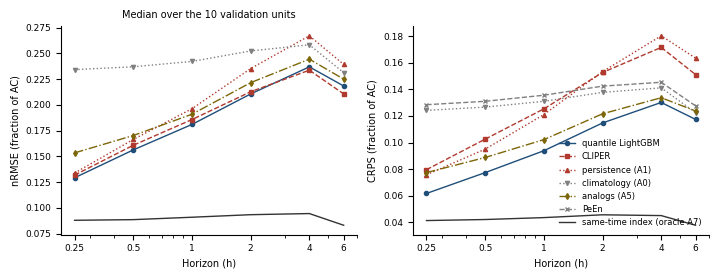

In [6]:
import matplotlib.pyplot as plt
A._style()
sty = {'LGB': ('#1f4e79', '-', 'o'), 'CLIPER': ('#b03a2e', '--', 's'), 'A1': ('#b03a2e', ':', '^'), 'A0': ('0.5', ':', 'v'),
       'A5': ('#7d6608', '-.', 'd'), 'PeEn': ('0.5', '--', 'x'), 'A7': ('0.2', '-', '')}
lab = {'LGB': 'quantile LightGBM', 'CLIPER': 'CLIPER', 'A1': 'persistence (A1)', 'A0': 'climatology (A0)', 'A5': 'analogs (A5)',
       'PeEn': 'PeEn', 'A7': 'same-time index (oracle A7)'}
hrs = np.array(FC.H) * 0.25
f6, ax = plt.subplots(1, 2, figsize=(7.2, 2.8))
for m, (c, ls, mk) in sty.items():
    for j, met in enumerate(['nRMSE', 'CRPS']):
        if met == 'nRMSE' and m == 'PeEn':
            continue
        y_ = med[(med.window == 'full') & (med.model == m)].set_index('h').loc[FC.H, met]
        ax[j].plot(hrs, y_, color=c, ls=ls, marker=mk, ms=3, lw=1, label=lab[m])
for j, met in enumerate(['nRMSE (fraction of AC)', 'CRPS (fraction of AC)']):
    ax[j].set_xscale('log'); ax[j].set_xticks(hrs); ax[j].set_xticklabels(['0.25', '0.5', '1', '2', '4', '6'])
    ax[j].set_xlabel('Horizon (h)'); ax[j].set_ylabel(met)
ax[1].legend(frameon=False, fontsize=6, loc='lower right')
ax[0].set_title('Median over the 10 validation units', fontsize=7); f6.tight_layout()

## Freeze of the LightGBM setting (part 2a) and outputs (all-or-nothing)

In [7]:
lgb_cfg = {
    'part': '2a', 'builds_on_frozen_part1': nb3['frozen1_sha256'], 'sensor_config': nb4['sensor_config_sha256'],
    'lgb_params': LGB_PARAMS, 'lgb_fixed': {k: v for k, v in FC.LGB_FIXED.items() if k != 'num_threads'},
    'lgb_target': 'change from persistence: k(t + h) - k(t), k(t) added back (D34)', 'horizon_models': 'one per horizon and quantile (54)',
    'rounds': {'max': FC.MAX_ROUNDS, 'early_stopping': FC.EARLY_STOP, 'valid_fraction_by_time': FC.VALID_FRAC, 'refit': 'whole window, best rounds'},
    'tuning_budget': {'settings': len(FC.LGB_GRID), 'folds': len(FOLDS), 'index': DEV, 'criterion': 'mean pinball, 9 quantiles x 6 horizons x 3 folds'},
    'features': FC.FEATURES, 'lags': C.N_LAGS, 'horizons': FC.H, 'quantiles': [float(t) for t in FC.TAUS],
    'issue': {'min_gtilde': C.ISSUE_MIN_GTILDE, 'min_donors': C.ISSUE_MIN_DONORS, 'last_target': '17:45 slot', 'score_min_gtilde': C.SCORE_MIN_GTILDE},
    'training': {'start': str(FC.TRAIN_START.date()), 'origins_days': list(FC.ORIGIN_DAYS), 'window': 'expanding, targets before the origin'},
    'composition': {'members': FC.M, 'index_levels': 'stratified (m - 0.5) / M', 'gain_levels': 'same levels, fixed permutation', 'seed': C.SEED,
                    'tails': 'linear, bounded to [0, 1.5]', 'point': 'member mean (RMSE), member median (MAE)'},
    'baselines': {'A0_days': FC.CLIM_DAYS, 'PeEn_days': FC.PEEN_DAYS, 'min_history_days': FC.MIN_HIST, 'A5_k': FC.KNN_K, 'CLIPER': 'least-squares weight on training pairs, bounded to [0, 1]'},
    'R1': {'metric': 'median over the 10 validation units of nRMSE at 1 h, full window, member mean, common slots',
           'lightgbm_reference': round(R1_REF, 6), 'rule': 'PVSetFormer is main only if lower (D25)'},
}
LGB_TEXT = yaml.safe_dump(lgb_cfg, sort_keys=True)
LGB_HASH = hashlib.sha256(LGB_TEXT.encode()).hexdigest()
summary = {'notebook': 'NB5a_development', 'environment': A.versions(), 'runtime_s': round(time.time() - t0, 1), 'workers': N_JOBS,
           'frozen1_sha256': nb3['frozen1_sha256'], 'sensor_config_sha256': nb4['sensor_config_sha256'], 'lgb_config_sha256': LGB_HASH,
           'dev_index': DEV, 'lgb_params': LGB_PARAMS, 'cv_best_pinball': float(cvs.iloc[0].pinball), 'cv_default_pinball': float(dflt.pinball),
           'R1_reference_nRMSE_1h': R1_REF, 'R1_units': r1_units.round(6).to_dict(),
           'median_nRMSE_full': {m: med[(med.window == 'full') & (med.model == m)].set_index('h')['nRMSE'].round(5).to_dict() for m in MODELS},
           'median_nRMSE_common': {m: med[(med.window == 'common') & (med.model == m)].set_index('h')['nRMSE'].round(5).to_dict() for m in MODELS},
           'median_skill_LGB': {c: skill[c].round(4).to_dict() for c in skill.columns},
           'wins_LGB_of_10': {c: wins[c].astype(int).to_dict() for c in wins.columns},
           'skipped_event_origin_h': int(diag.skipped.sum())}
tables = {'cv_grid': cv, 'cv_summary': cvs, 'val_scores': sc, 'val_medians': med, 'val_skill': sk.reset_index(),
          'val_diag': diag, 'val_priors': pri_chk}
out = A.write_outputs('nb5a_dev', tables, summary, {'fig_validation_horizon': f6}, parquet={'val_forecasts': fc},
                      texts={'lgb_config_part2a.yaml': LGB_TEXT})
print('LightGBM config (part 2a) sha256:', LGB_HASH)
print('written to', out, '|', sorted(x.name for x in out.iterdir()))

LightGBM config (part 2a) sha256: d03bb0b86827009edcc4d37bd6ebb88de1697e1c8aac60646e988f4e9fe75abe
written to C:\Users\Dell\Desktop\phd_ehtp\pv paper\results\nb5a_dev | ['cv_grid.csv', 'cv_summary.csv', 'figures', 'lgb_config_part2a.yaml', 'summary.json', 'val_diag.csv', 'val_forecasts.parquet', 'val_medians.csv', 'val_priors.csv', 'val_scores.csv', 'val_skill.csv']
